# LAB 03 — Stellar Activity & Planetary Habitability

**Astrobiologija**

**Istraživačko pitanje:** Kako aktivnost zvezde komplikuje jednostavnu klasifikaciju nastanjivosti planeta?

## 1. Zašto nastanjiva zona nije dovoljna?

Klasična nastanjiva zona (HZ) određuje opseg udaljenosti u kome, pod odgovarajućim atmosferskim uslovima, na površini stenovite planete **može** postojati tečna voda. Položaj u HZ nije dokaz nastanjivosti. Aktivnost zvezde utiče na atmosferu i površinsko okruženje kroz:

- **Zvezdane pege i rotaciju** — promenljiva osvetljenost dok pege i aktivne oblasti ulaze i izlaze iz vidnog polja.
- **Bljeskove (flares)** — nagle događaje povezane sa oslobađanjem magnetne energije, ponekad praćene visokenergijskim zračenjem i česticama.
- **XUV zračenje** (X-zraci + ekstremni UV) — može zagrevati i širiti gornju atmosferu i doprineti njenom gubitku.
- **Dugoročni razvoj aktivnosti** — mlade zvezde, u proseku, često su aktivnije, a XUV evolucija može biti važna za atmosfersku istoriju.


## 2. Šta TESS meri?

TESS (Transiting Exoplanet Survey Satellite) meri osvetljenost zvezda tokom vremena. **Svetlosna kriva** je niz $(t_i,F_i,\sigma_i)$: vremena, fluksevi i njihove greške. Različiti TESS podaci imaju različite kadence; njihovu stvarnu vrednost određujemo iz metapodataka i/ili vremenskih razlika, a ne pretpostavljamo unapred.

**Vremenska skala:** Za TESS svetlosne krive vreme je najčešće u **BTJD = BJD(TDB) − 2 457 000**, gde je BJD baricentrično korigovani julijanski datum. Izvorni format i skalu proveravamo u objektu.

**SAP vs PDCSAP:** SAP je aperturska fotometrija; PDCSAP je proizvod sa korekcijama sistematskih efekata. Korekcija može ukloniti i deo stvarne dugoperiodične varijabilnosti.

**Artefakti:** razmaci u podacima, promena pozadine, impulsi kosmičkih zraka, instrumentalni skokovi, kvalitetom označena merenja, sistematski efekti vezani za letelicu i kontaminacija susednim izvorima.

**Pravila naučne provere:** pojedinačan odstupajući piksel/uzorak nije potvrđen flare; vrh periodograma nije automatski period rotacije; jak dugotrajan trend nije automatski signal zvezde.

## 3. Pokazni kod: biblioteke i osnovni grafikon

U Google Colab-u prvo instalirati biblioteke. Primer ispod **nije TESS posmatranje** — služi samo za objašnjenje normalizacije i grafičkog prikaza. Svaka analiza ciljne zvezde dalje mora koristiti stvarni preuzeti proizvod.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk
from astropy.timeseries import LombScargle
from pathlib import Path

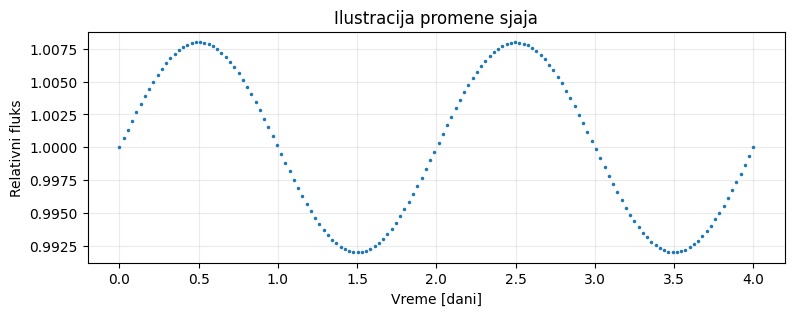

In [4]:
# Isključivo ilustrativni primer (NE TESS podaci):
t_demo = np.linspace(0, 4, 150)
f_demo = 1 + 0.008 * np.sin(2 * np.pi * t_demo / 2)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t_demo, f_demo, '.', markersize=3)
ax.set(xlabel="Vreme [dani]", ylabel="Relativni fluks",
       title="Ilustracija promene sjaja")
ax.grid(alpha=0.25)
plt.show()

## 4. Stvarni podaci: pouzdano pretraživanje i izbor TESS podataka

Sledeći **pokazni deo** demonstrira realnu pretragu arhive. Podrazumevana meta je **Pi Mensae / TIC 261136679, sektor 1**, poznati demonstracioni primer iz TESS dokumentacije. Prisutnost konkretnog primera zavisi od MAST servisa.

- `DATA_MODE = "live"` znači da je preuzimanje obavezno.
- `DATA_MODE = "local"` dozvoljen je **samo** za unapred sačuvan, originalni FITS sa dokumentovanim izvorom (npr. kopiju MAST primera). Nema generisanja zamenskih uzoraka.


In [5]:
DATA_MODE = "live"   # "live" ili "local" — nikad sintetički fallback
TARGET = "TIC 261136679"  # Pi Mensae: primer, može se promeniti nakon provere
SECTOR = 1
AUTHOR = "SPOC"         # ako nema rezultata, istražiti dostupne autore u pretrazi
LOCAL_FITS = ""         # samo za DATA_MODE="local": putanja do autentičnog FITS-a
LOCAL_SOURCE_URL = ""   # MAST URL/DOI/identifikator, obavezno za lokalnu kopiju

assert DATA_MODE in ("live", "local")
if DATA_MODE == "local":
    assert LOCAL_FITS and Path(LOCAL_FITS).is_file(), "Nedostaje pravi FITS proizvod."
    assert LOCAL_SOURCE_URL.strip(), "Upiši izvor originalnog FITS proizvoda."

In [6]:
if DATA_MODE == "live":
    try:
        results = lk.search_lightcurve(TARGET, mission="TESS", sector=SECTOR)
    except Exception as exc:
        raise RuntimeError("MAST pretraga nije uspela. Prekinuti rad i proveriti mrežu.") from exc
    if len(results) == 0:
        raise RuntimeError("Nema TESS podatka za izabranu metu/sektor. Izabrati proverenu metu.")
    display(results.table)
else:
    print("LOCAL režim: koristi se prethodno dokumentovan originalni FITS.")

intentType,obs_collection,provenance_name,instrument_name,project,filters,wave_region,target_name,target_classification,obs_id,s_ra,s_dec,dataproduct_type,proposal_pi,calib_level,t_min,t_max,t_exptime,wavelength_region,em_min,em_max,obs_title,t_obs_release,proposal_id,proposal_type,sequence_number,s_region,jpegURL,dataURL,dataRights,mtFlag,srcDen,obsid,objID,wave_min,wave_max,exptime,distance,obsID,obs_collection_products,dataproduct_type_products,description,type,dataURI,productType,productGroupDescription,productSubGroupDescription,productDocumentationURL,project_products,prvversion,proposal_id_products,productFilename,size,parent_obsid,dataRights_products,calib_level_products,filters_products,author,mission,#,year,sort_order
,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,s,arcsec,,,,,,,,,,,,,,,,,,,,,,,,
str7,str4,str17,str10,str4,str4,str7,str9,str1,str73,float64,float64,str10,str19,int64,float64,float64,float64,str7,float64,float64,str28,float64,str31,str1,int64,str65,str96,str129,str6,bool,float64,str9,str10,float64,float64,float64,float64,str9,str4,str10,str33,str1,str129,str7,str28,str3,str1,str17,str20,str31,str78,int64,str9,str6,int64,str4,str17,object,object,int64,int64
science,TESS,SPOC,Photometer,TESS,TESS,Optical,261136679,--,tess2018206045859-s0001-0000000261136679-0120-s,84.2911879979852,-80.4691197969941,timeseries,"Ricker, George",3,58324.7940765625,58352.67695946759,120.0,Optical,600.0,1000.0,--,58458.5833333,G011183_G011132_G011048_G011250,--,1,CIRCLE 84.291188 -80.4691198 0.00138889,--,mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,PUBLIC,False,nan,60835895,110345495,600.0,1000.0,120,0.0,60835895,TESS,timeseries,Light curves,S,mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,SCIENCE,Minimum Recommended Products,LC,--,SPOC,b11c787608,G011183_G011132_G011048_G011250,tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,2039040,60835895,PUBLIC,3,TESS,SPOC,TESS Sector 01,None,2018,1
science,HLSP,TESS-SPOC,Photometer,TESS,TESS,Optical,261136679,--,hlsp_tess-spoc_tess_phot_0000000261136679-s0001_tess_v1_tp,84.2911879979852,-80.4691197969941,timeseries,Douglas A. Caldwell,4,58324.81352074074,58352.66723747685,1800.0,Optical,600.0,1000.0,--,59309.55839107,N/A,--,1,CIRCLE ICRS 84.29118800 -80.46911980 0.00111111,--,mast:HLSP/tess-spoc/s0001/target/0000/0002/6113/6679/hlsp_tess-spoc_tess_phot_0000000261136679-s0001_tess_v1_lc.fits,PUBLIC,False,nan,59804479,105608205,600.0,1000.0,1800,0.0,59804479,HLSP,timeseries,FITS,C,mast:HLSP/tess-spoc/s0001/target/0000/0002/6113/6679/hlsp_tess-spoc_tess_phot_0000000261136679-s0001_tess_v1_lc.fits,SCIENCE,Minimum Recommended Products,--,--,TESS-SPOC,42,N/A,hlsp_tess-spoc_tess_phot_0000000261136679-s0001_tess_v1_lc.fits,164160,59804479,PUBLIC,4,TESS,TESS-SPOC,TESS Sector 01,None,2018,2
science,HLSP,QLP,Photometer,TESS,TESS,Optical,261136679,--,hlsp_qlp_tess_ffi_s0001-0000000261136679_tess_v01_llc,84.291198,-80.469143,timeseries,Chelsea X. Huang,4,58324.82476052,58352.65764309,1800.0,Optical,600.0,1000.0,--,59260.77603004,N/A,--,1,CIRCLE ICRS 84.29119800 -80.46914300 0.00111111,--,mast:HLSP/qlp/s0001/0000/0002/6113/6679/hlsp_qlp_tess_ffi_s0001-0000000261136679_tess_v01_llc.fits,PUBLIC,False,nan,59455369,103396971,600.0,1000.0,1800,0.0,59455369,HLSP,timeseries,FITS,C,mast:HLSP/qlp/s0001/0000/0002/6113/6679/hlsp_qlp_tess_ffi_s0001-0000000261136679_tess_v01_llc.fits,SCIENCE,Minimum Recommended Products,--,--,QLP,--,N/A,hlsp_qlp_tess_ffi_s0001-0000000261136679_tess_v01_llc.fits,80640,59455369,PUBLIC,4,TESS,QLP,TESS Sector 01,None,2018,3
science,HLSP,GSFC-ELEANOR-LITE,Photometer,TESS,TESS,Optical,261136679,--,hlsp_gsfc-eleanor-lite_tess_ffi_s0001-0000000261136679_tess_v1.0_lc,84.2911879979852,-80.4691197969941,timeseries,Brian P. Powell,4,58324.81304390046,58352.666903854166,1800.0,Optical,600.0,1000.0,--,59740.0,N/A,--,1,CIRCLE ICRS 84.29118800 -80.46911980 0.00111111,--,mast:HLSP/gsfc-eleanor-lite/s0001/0000/0002/6113/6679/hlsp_gsfc-eleanor-li

In [7]:
if DATA_MODE == "live":
    selected = results[results.table["author"] == AUTHOR]
    if len(selected) == 0:
        raise RuntimeError(f"Autor {AUTHOR!r} nije dostupan. Pregledaj tabelu rezultata i izmeni AUTHOR.")
    if len(selected) > 1:
        print("Postoji više proizvoda za autora; primer koristi prvi. Uporediti kadence!")
    selected = selected[0:1]
    display(selected.table)
    try:
        lc_raw = selected.download(quality_bitmask="none")
    except Exception as exc:
        raise RuntimeError("Preuzimanje FITS svetlosne krive nije uspelo; nema zamenskih podataka.") from exc
else:
    lc_raw = lk.read(LOCAL_FITS, quality_bitmask="none")

if lc_raw is None or len(lc_raw) == 0:
    raise RuntimeError("FITS svetlosna kriva je prazna.")
print(lc_raw)

intentType,obs_collection,provenance_name,instrument_name,project,filters,wave_region,target_name,target_classification,obs_id,s_ra,s_dec,dataproduct_type,proposal_pi,calib_level,t_min,t_max,t_exptime,wavelength_region,em_min,em_max,obs_title,t_obs_release,proposal_id,proposal_type,sequence_number,s_region,jpegURL,dataURL,dataRights,mtFlag,srcDen,obsid,objID,wave_min,wave_max,exptime,distance,obsID,obs_collection_products,dataproduct_type_products,description,type,dataURI,productType,productGroupDescription,productSubGroupDescription,productDocumentationURL,project_products,prvversion,proposal_id_products,productFilename,size,parent_obsid,dataRights_products,calib_level_products,filters_products,author,mission,#,year,sort_order
,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,s,arcsec,,,,,,,,,,,,,,,,,,,,,,,,
str7,str4,str17,str10,str4,str4,str7,str9,str1,str73,float64,float64,str10,str19,int64,float64,float64,float64,str7,float64,float64,str28,float64,str31,str1,int64,str65,str96,str129,str6,bool,float64,str9,str10,float64,float64,float64,float64,str9,str4,str10,str33,str1,str129,str7,str28,str3,str1,str17,str20,str31,str78,int64,str9,str6,int64,str4,str17,object,object,int64,int64
science,TESS,SPOC,Photometer,TESS,TESS,Optical,261136679,--,tess2018206045859-s0001-0000000261136679-0120-s,84.2911879979852,-80.4691197969941,timeseries,"Ricker, George",3,58324.7940765625,58352.67695946759,120.0,Optical,600.0,1000.0,--,58458.5833333,G011183_G011132_G011048_G011250,--,1,CIRCLE 84.291188 -80.4691198 0.00138889,--,mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,PUBLIC,False,nan,60835895,110345495,600.0,1000.0,120,0.0,60835895,TESS,timeseries,Light curves,S,mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,SCIENCE,Minimum Recommended Products,LC,--,SPOC,b11c787608,G011183_G011132_G011048_G011250,tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,2039040,60835895,PUBLIC,3,TESS,SPOC,TESS Sector 01,None,2018,1


       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
 1325.295571625472            ——— ...            ———            ———
1325.2969604950604  1.4641956e+06 ...  9.0913408e-02 -7.2966635e-02
1325.2983493645327  1.4643365e+06 ...  6.2022530e-02 -1.0871942e-01
 1325.299738234005  1.4643485e+06 ...  6.1673984e-02 -1.1394957e-01
 1325.301127103477  1.4643674e+06 ...  6.0909923e-02 -1.2573890e-01
1325.3025159730657  1.4642560e+06 ...  5.3837594e-02 -1.2532526e-01
 1325.303904842538  1.4644681e+06 ...  5.2977830e-02 -1.2562653e-01
1325.3052937121265  1.4643586e+06 ...  5.7222184e-02 -1.3051888e-01
1325.3066825815986  1.4643564e+06 ...  5.5443291e-02 -1.2712292e-01
               ...            ... ...            ...            ...
1353.1645661947705  1.4646795e+06 ...  5.5579260e-02 -1.1038263e-02
1353.1659550506233  1.4649392e+06 ...  6.0031198

## 5. Pokazni kod: rad sa Lightkurve objektom

`remove_nans()` uklanja neispravne vrednosti. `quality_bitmask="none"` je namerno zadržao sve kadence kako bi se video efekat kvaliteta; kvalitet zatim proveravamo eksplicitno. Kod `quality == 0` jednostavan je **konzervativan primer**, ali ne zamenjuje razumevanje značenja pojedinih bitova zastavice.

**Pažnja:** `flatten()` ili neki drugi detrending može potisnuti sporu rotacionu modulaciju i deformisati flare. Za potragu rotacionog perioda raditi i sa nedetrendovanom serijom, a filtriranje vršiti uz opravdanje.

Broj učitanih kadenci: 19261
Format vremena: btjd
Skala vremena: tdb
Kolone: ['time', 'flux', 'flux_err', 'timecorr', 'cadenceno', 'centroid_col', 'centroid_row', 'sap_flux', 'sap_flux_err', 'sap_bkg', 'sap_bkg_err', 'pdcsap_flux', 'pdcsap_flux_err', 'quality', 'psf_centr1', 'psf_centr1_err', 'psf_centr2', 'psf_centr2_err', 'mom_centr1', 'mom_centr1_err', 'mom_centr2', 'mom_centr2_err', 'pos_corr1', 'pos_corr2']


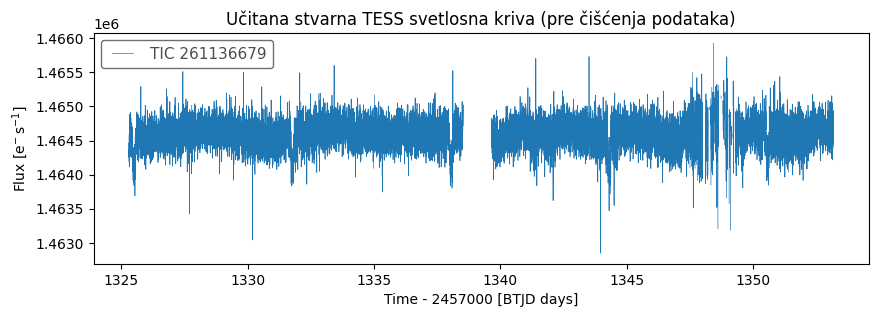

In [8]:
print("Broj učitanih kadenci:", len(lc_raw))
print("Format vremena:", lc_raw.time.format)
print("Skala vremena:", lc_raw.time.scale)
print("Kolone:", list(lc_raw.columns))

fig, ax = plt.subplots(figsize=(10, 3))
lc_raw.plot(ax=ax)
ax.set_title("Učitana stvarna TESS svetlosna kriva (pre čišćenja podataka)")
plt.show()

In [9]:
# Minimalna demonstracija samo jedne operacije: uklanjanje NaN
lc_no_nan = lc_raw.remove_nans()
print("Pre:", len(lc_raw), "Posle remove_nans:", len(lc_no_nan))

# Dalje filtriranje, normalizaciju, izbor trendova i analizu rade studenti.

Pre: 19261 Posle remove_nans: 18279


### Zadatak 1
1. Iz prikazane tabele dostupnih podataka obrazložite izbor konkretnog primera: target, sektor, autor i kadenca. U slučaju više primera uporedite najmanje dva.
2. Ispišite **identifikator ili URL proizvoda** iz arhive i vremensku skalu, kao i broj merenja.
3. Izračunajte medijanu razlika između **susednih validnih vremenskih oznaka** u minutima. Da li odgovara očekivanoj kadenci? Objasnite zašto razmaci mogu biti duži.
4. Objasnite razliku između SAP i PDCSAP fotometrije i navedite zašto je to bitno za aktivnost zvezde.


In [10]:
def arr(x):
    x = getattr(x, "value", x)
    return np.ma.filled(np.ma.asarray(x, dtype=float), np.nan)

# 1.1 svi dostupni proizvodi za metu
tab_all = results.table
cols = [c for c in ["target_name", "sequence_number", "author", "exptime", "productFilename", "distance"] if c in tab_all.colnames]

print("Svi podaci za", TARGET, "sektor", SECTOR)
display(tab_all[cols])

print("\nIzabrano:")
print(f"target = {TARGET}, sektor = {SECTOR}, autor = {AUTHOR}, "
      f"exptime = {selected.table['exptime'][0]} s" if "exptime" in selected.table.colnames else "")

# 1.2 identifikator, vremenska skala, broj merenja
tab = selected.table
for c in ("productFilename", "obs_id", "obsID", "dataURI", "dataURL"):
    if c in tab.colnames:
        print(f"{c:16s}: {tab[c][0]}")
if "dataURI" in tab.colnames:
    print("MAST URL: https://mast.stsci.edu/api/v0.1/Download/file?uri=" + str(tab["dataURI"][0]))
print("Lokalni FITS:", lc_raw.meta.get("FILENAME"))
print("Format vremena:", lc_raw.time.format, " skala:", lc_raw.time.scale)
print("Izvor fluksa:", lc_raw.meta.get("FLUX_ORIGIN", "pdcsap_flux (podrazumevano u Lightkurve-u)"))

t_all = arr(lc_raw.time)
f_all = arr(lc_raw.flux)
valid = np.isfinite(t_all) & np.isfinite(f_all)
print(f"Ukupno kadenci: {len(lc_raw)}, sa konačnim vremenom i fluksom: {valid.sum()} "
      f" NaN: {(~valid).sum()}")

# 1.3 medijalna razlika izmedju susednih validnih vremenskih oznaka
dt_min = np.diff(t_all[valid]) * 24 * 60
med_dt = np.median(dt_min)
print(f"\nMedijana delta t = {med_dt:.4f} min (očekivano za SPOC kratku kadencu: 2 min)")
print(f"delta t > 1.5*medijana: {(dt_min > 1.5*med_dt).sum()} razmaka, najveći razmak: {dt_min.max()/60:.2f} h "
      f"({dt_min.max()/1440:.2f} d)")


Svi podaci za TIC 261136679 sektor 1


target_name,sequence_number,author,exptime,productFilename,distance
,,,s,,arcsec
str9,int64,str17,float64,str78,float64
261136679,1,SPOC,120,tess2018206045859-s0001-0000000261136679-0120-s_lc.fits,0.0
261136679,1,TESS-SPOC,1800,hlsp_tess-spoc_tess_phot_0000000261136679-s0001_tess_v1_lc.fits,0.0
261136679,1,QLP,1800,hlsp_qlp_tess_ffi_s0001-0000000261136679_tess_v01_llc.fits,0.0
261136679,1,GSFC-ELEANOR-LITE,1800,hlsp_gsfc-eleanor-lite_tess_ffi_s0001-0000000261136679_tess_v1.0_lc.fits,0.0
261136679,1,TARS,1800,hlsp_tars_tess_ffi_s0001-0000000261136679_tess_v01_lc.fits,0.0
261136679,1,TASOC,120,hlsp_tasoc_tess_tpf_tic00261136679-s0001-cam4-ccd2-c0120_tess_v05_cbv-lc.fits,0.0
261136679,1,TASOC,1800,hlsp_tasoc_tess_ffi_tic00261136679-s0001-cam4-ccd2-c1800_tess_v05_cbv-lc.fits,0.0
261136679,1,TASOC,1800,hlsp_tasoc_tess_ffi_tic00261136679-s0001-cam4-ccd2-c1800_tess_v05_ens-lc.fits,0.0



Izabrano:
target = TIC 261136679, sektor = 1, autor = SPOC, exptime = 120.0 s
productFilename : tess2018206045859-s0001-0000000261136679-0120-s_lc.fits
obs_id          : tess2018206045859-s0001-0000000261136679-0120-s
obsID           : 60835895
dataURI         : mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits
dataURL         : mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits
MAST URL: https://mast.stsci.edu/api/v0.1/Download/file?uri=mast:TESS/product/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits
Lokalni FITS: /home/arekysa/.lightkurve/cache/mastDownload/TESS/tess2018206045859-s0001-0000000261136679-0120-s/tess2018206045859-s0001-0000000261136679-0120-s_lc.fits
Format vremena: btjd  skala: tdb
Izvor fluksa: pdcsap_flux
Ukupno kadenci: 19261, sa konačnim vremenom i fluksom: 18279  NaN: 982

Medijana delta t = 2.0000 min (očekivano za SPOC kratku kadencu: 2 min)
delta t > 1.5*medijana: 286 razmaka, najveći razmak: 27.23 h (1.1

Kako se odgovori za 1.1 i 1.2 vide iz print ispisa fokus ce biti na odgovore za 1.3 i 1.4.

Medijana $\Delta t$  iznosi **2,0000 min**, što tačno odgovara nominalnoj kadenci SPOC proizvoda (120 s). Medijana je robusna na retke duže razmake, pa potvrđuje da je ovo zaista 2-minutna serija.

Pronađeno je **286** razmaka dužih od 1,5 $\times$ medijana. Najveći je **27,23 h (1,13 d)**, a to je pauza sredinom sektora, kada TESS prekida posmatranje radi slanja podataka na Zemlju (između dve orbite). Ostali razmaci su kraći i najverovatnije nastaju jer su kadence sa NaN fluksom (982) preskočene pri računanju $\Delta t$ . Razlozi za NaN i duže razmake su kosmički zraci, rasejana svetlost, momentum dump i kadence koje je PDC obrada odbacila.

**SAP** (Simple Aperture Photometry) je zbir fluksa piksela u aperturi uz oduzetu pozadinu. Sadrži i stvarnu promenljivost zvezde. **PDCSAP** (Presearch Data Conditioning SAP) je SAP fluks iz kog su pomoću *cotrending basis vectors* uklonjeni zajednički sistematski trendovi, a ispravljen je i za kontaminaciju susednim zvezdama i deo fluksa izvan aperture (crowding/flux fraction).

Za aktivnost zvezde je to bitno iz dva razloga:
- PDC može **potisnuti ili izobličiti dugoperiodičnu modulaciju** (rotacija od više dana), pa se period proverava i u SAP-u.
- SAP može **lažno uneti instrumentalni trend** kao „rotaciju“, dok je PDCSAP pouzdaniji za amplitude jer je korigovan za razblaživanje.


### Zadatak 2

1. Prikažite raspodelu `quality` vrednosti i izbrojte kadence koje su potencijalno problematične.
2. Napravite „čistu” svetlosnu krivu: obrazložite izbor quality maske i uklonite NaN.
3. Normalizujte fluks i sačuvajte seriju **pre detrendinga**.
4. Po želji napravite blago detrendovanu verziju i pokažite **isti vremenski interval** pre i posle korekcije. Objasnite šta je moglo biti uklonjeno.
5. Proverite da li u seriji postoje skokovi na granicama vremenskih praznina ili promene pozadine.


,quality,broj kadenci,znecenje bitova
0,0,18264,bez zastavice
1,8,1,Earth point
2,32,18,Desaturation event
3,128,910,Manual exclude
4,144,1,Argabrightening; Manual exclude
5,160,22,Desaturation event; Manual exclude
6,164,30,Coarse point; Desaturation event; Manual exclude
7,512,15,Impulsive outlier


Kadence sa bilo kojom zastavicom (quality != 0): 997 (5.18 %)
Kadence odbacene podrazumevanom Lightkurve maskom: 997
Kadence sa NaN vrednoscu: 982


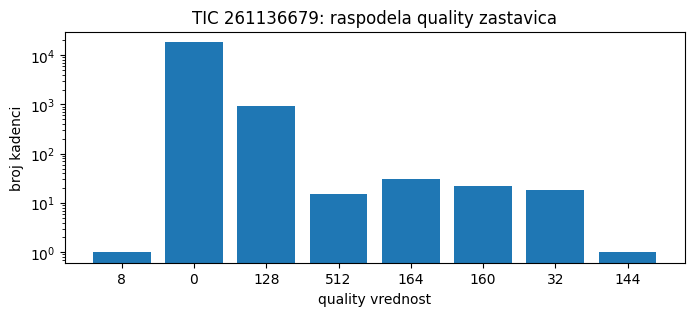

Cista kriva: 18264 od 19261 kadenci (94.8 %); odbaceno 997
Medijana fluksa posle normalizacije: 1.0
Robustan sum po kadenci: 112.78888627206392 ppm
Prozor flatten(): 1441 kadenci ≈ 2.00 d


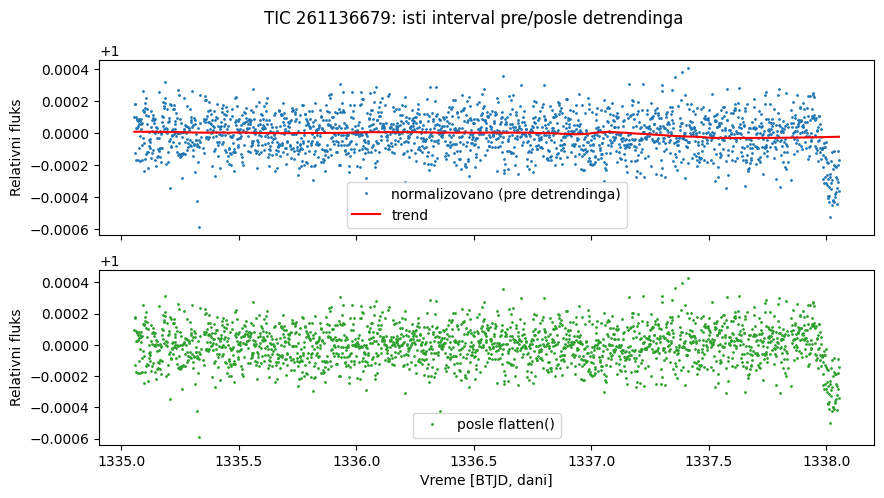

Praznine > 0.2 d: 1


,kraj segmenta,početak sledećeg,razmak [d],skok fluksa [ppm],skok/šum (σ)
0,1338.521779,1339.656478,1.1347,-124.543905,4.416886


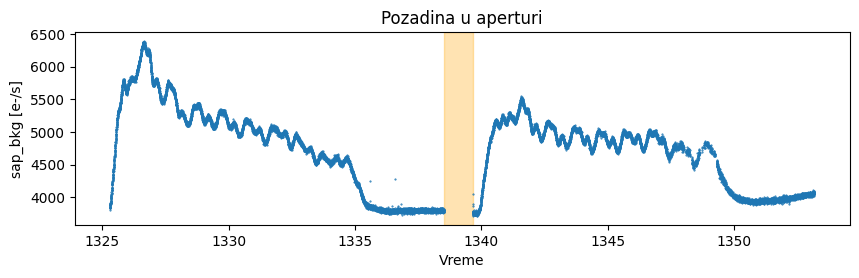

Pozadina: medijana 4835.1, 99. percentil 6223.7 e-/s


In [11]:
from collections import Counter
from lightkurve.utils import TessQualityFlags as TQF

# raspodela vrednosti
q = np.asarray(lc_raw.quality).astype(int)
cnt = Counter(q.tolist())
rows = [(v, n, "; ".join(TQF.decode(v)) if v!=0 else "bez zastavice") for v, n in sorted(cnt.items())]
qtab = pd.DataFrame(rows, columns=["quality", "broj kadenci", "znecenje bitova"])
display(qtab)

bad_any = q != 0
bad_default = (q & TQF.DEFAULT_BITMASK) != 0
print(f"Kadence sa bilo kojom zastavicom (quality != 0): {bad_any.sum()} ({100*bad_any.mean():.2f} %)")
print(f"Kadence odbacene podrazumevanom Lightkurve maskom: {bad_default.sum()}")
print(f"Kadence sa NaN vrednoscu: {(~np.isfinite(arr(lc_raw.flux))).sum()}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar([str(v) for v in cnt], list(cnt.values()))
ax.set_yscale("log"); ax.set(xlabel="quality vrednost", ylabel="broj kadenci",
                             title=f"{TARGET}: raspodela quality zastavica")
plt.show()


# 2.2 cista kriva sa uklonjenim NaN 
good = (q == 0) & np.isfinite(arr(lc_raw.time)) & np.isfinite(arr(lc_raw.flux))
lc_clean = lc_raw[good]
print(f"Cista kriva: {len(lc_clean)} od {len(lc_raw)} kadenci "
      f"({100*len(lc_clean)/len(lc_raw):.1f} %); odbaceno {len(lc_raw)-len(lc_clean)}")


# 2.3 normalizacija cuvamo pre detrending
lc_norm = lc_clean.normalize()
lc_pre_detrending = lc_norm.copy()
t_n, f_n = arr(lc_norm.time), arr(lc_norm.flux)
sig_pp = 1.4826 * np.median(np.abs(np.diff(f_n) - np.median(np.diff(f_n)))) / np.sqrt(2)
print(f"Medijana fluksa posle normalizacije: {np.median(f_n)}")
print(f"Robustan sum po kadenci: {sig_pp*1e6} ppm")

# 2.4 blagi detrend verzija
dt_d = np.median(np.diff(t_n))
win = int(round(2.0 / dt_d)); win += (win % 2 == 0)
lc_flat, lc_trend = lc_norm.flatten(window_length=win, polyorder=2, niters=3, sigma=5,
                                    break_tolerance=50, return_trend=True)
print(f"Prozor flatten(): {win} kadenci ≈ {win*dt_d:.2f} d")


t0 = t_n.min() + 0.35 * (t_n.max() - t_n.min())      # isti interval pre i posle
sel = (t_n > t0) & (t_n < t0 + 3.0)
fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axs[0].plot(t_n[sel], f_n[sel], ".", ms=2, label="normalizovano (pre detrendinga)")
axs[0].plot(arr(lc_trend.time)[sel], arr(lc_trend.flux)[sel], "r-", lw=1.5, label="trend")
axs[0].legend(); axs[0].set_ylabel("Relativni fluks")
axs[1].plot(arr(lc_flat.time)[sel], arr(lc_flat.flux)[sel], ".", ms=2, c="C2", label="posle flatten()")
axs[1].legend(); axs[1].set(xlabel=f"Vreme [{lc_raw.time.format.upper()}, dani]", ylabel="Relativni fluks")
fig.suptitle(f"{TARGET}: isti interval pre/posle detrendinga")
plt.show()

# 2.5 praznine, skokovi na granicama i pozadina
GAP_THR = 0.2   # dana (≈ 100 kadenci od 2 min)
gi = np.where(np.diff(t_n) > GAP_THR)[0]
rows = []
for i in gi:
    b = f_n[max(0, i-49):i+1]; a = f_n[i+1:i+51]
    step = np.median(a) - np.median(b)
    err = sig_pp * np.sqrt(1/len(a) + 1/len(b)) * 1.25
    rows.append((t_n[i], t_n[i+1], t_n[i+1]-t_n[i], 1e6*step, abs(step)/err))
gap_df = pd.DataFrame(rows, columns=["kraj segmenta", "početak sledećeg", "razmak [d]",
                                     "skok fluksa [ppm]", "skok/šum (σ)"])
print(f"Praznine > {GAP_THR} d: {len(gap_df)}")
display(gap_df)

if "sap_bkg" in lc_clean.columns:
    bkg = arr(lc_clean["sap_bkg"])
    fig, ax = plt.subplots(figsize=(10, 2.5))
    ax.plot(t_n, bkg, ".", ms=1); ax.set(xlabel="Vreme", ylabel="sap_bkg [e-/s]", title="Pozadina u aperturi")
    for i in gi: ax.axvspan(t_n[i], t_n[i+1], color="orange", alpha=0.3)
    plt.show()
    print("Pozadina: medijana %.1f, 99. percentil %.1f e-/s" % (np.median(bkg), np.percentile(bkg, 99)))
else:
    print("Kolona sap_bkg nije dostupna u ovom proizvodu.")


**Izbor maske**

Izabrana je `quality == 0` jer je cilj potraga za flare-ovima: označene kadence mogu imitirati kratke skokove fluksa, a posebno su opasne 15 kadenci sa *Impulsive outlier* zastavicom. Cena je mala: odbačeno je 997 kadenci (5,2 %), a čista kriva ima **18 264** kadenci. Zbog preklapanja sa NaN vrednostima, stvarno dodatno uklonjeno zbog zastavica je samo 15 tačaka u odnosu na običan `remove_nans()`. Blaža maska bi zato dala praktično isti rezultat, a stroža (`hard`) bi odbacila više podataka bez jasne koristi.


**Detrending**

Savitzky–Golay prozor od 1441 kadence (≈ 2,00 d) ima efekat samo na promene duže od ~dan. Na prikazanom intervalu (BTJD 1335–1338) trend je skoro ravan i pada za samo ~200 ppm kroz tri dana, pa su krive pre i posle detrendinga gotovo iste; vidljiv rasap je dominantno šum od ~113 ppm. Zato ovde detrending ne menja slučajne varijacije, ali bi mogao da ukloni spor, stvaran signal (rotacionu modulaciju sa periodom ≳ 2 d, amplitudu ispod nekoliko stotina ppm), pa se Lomb–Scargle radi na seriji **pre** detrendinga.

Primećuje se i pad fluksa od ≈ 300–400 ppm na samom kraju prikazanog intervala (BTJD ≈ 1338). Taj pad **ostaje i posle** `flatten()`, jer je prekratak da bi ga prozor od 2 d uhvatio. Ne može se zaključiti da je to stvaran signal zvezde: nalazi se u poslednjem delu orbite, pre prekida od 1,13 d.

**Praznine, skokovi i pozadina**

Postoji jedna praznina duža od 0,2 d, između BTJD 1338,52 i 1339,66 (1,13 d), što je pauza sredinom sektora (slanje podataka). Skok medijane fluksa preko praznine (50 tačaka pre i posle) iznosi **−125 ppm**, što je **≈ 4,4σ**. To je statistički značajno, pa je offset između dve orbite verovatno instrumentalan, ali je male amplitude (red veličine kao šum jedne kadence, 113 ppm). Deo skoka potiče i od opisanog pada fluksa pre praznine, jer se računa iz poslednjih 50 kadenci.


### Zadatak 3

1. Nacrtajte celu očišćenu svetlosnu krivu sa osama, jedinicama i nazivom targeta.
2. Obeležite najmanje jedan vremenski prekid ili sumnjiv instrumentalni deo, **ako postoji**.
3. Uvećajte jedan zanimljiv segment i napišite da li je oblik više nalik periodičnoj modulaciji, impulsu, tranzitu ili sistematici — bez preuranjenog zaključka.


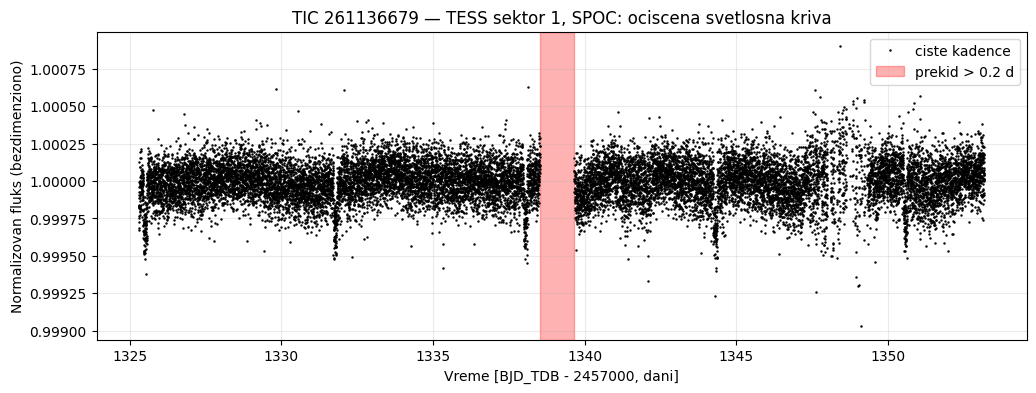

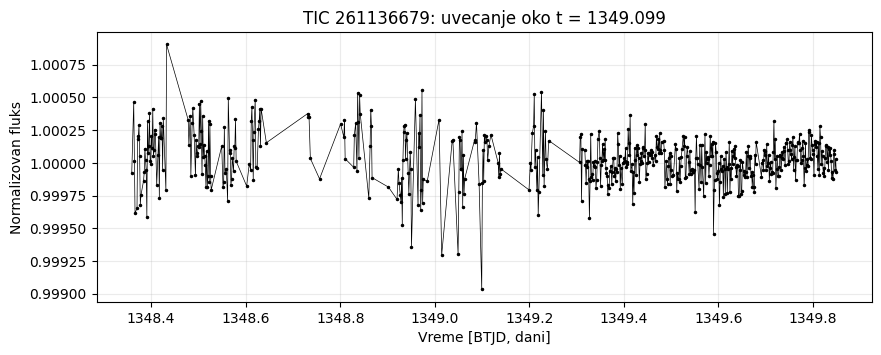

Segment: 581 kadenci, raspon 1872 ppm, pozicija maksimuma 1348.433, minimuma 1349.099


In [12]:
t_n, f_n = arr(lc_norm.time), arr(lc_norm.flux)
GAP_THR = 0.2
gi = np.where(np.diff(t_n) > GAP_THR)[0]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_n, f_n, ".", ms=1.5, color="black", label="ciste kadence")

# 3.2 prekidi
for k, i in enumerate(gi):                                  
    ax.axvspan(t_n[i], t_n[i+1], color="red", alpha=0.3,
               label="prekid > 0.2 d" if k == 0 else None)
ax.set(xlabel="Vreme [BJD_TDB - 2457000, dani]",
       ylabel="Normalizovan fluks (bezdimenziono)",
       title=f"{TARGET} — TESS sektor {SECTOR}, {AUTHOR}: ociscena svetlosna kriva")
ax.legend(loc="upper right"); ax.grid(alpha=0.25)
plt.show()

# 3.3 uvecanje na zanimljiv segment
ZOOM_CENTER = None
HALF = 0.75   # dana
if ZOOM_CENTER is None:
    base = pd.Series(f_n, index=pd.to_datetime(t_n, unit="D")).rolling("1D", center=True).median().values
    dev = np.abs(f_n - base)
    ZOOM_CENTER = t_n[np.nanargmax(dev)]
m = (t_n > ZOOM_CENTER - HALF) & (t_n < ZOOM_CENTER + HALF)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t_n[m], f_n[m], ".-", ms=3, lw=0.5, color="black")
ax.set(xlabel="Vreme [BTJD, dani]", ylabel="Normalizovan fluks",
       title=f"{TARGET}: uvecanje oko t = {ZOOM_CENTER:.3f}")
ax.grid(alpha=0.25); plt.show()
seg = f_n[m]
print(f"Segment: {m.sum()} kadenci, raspon {1e6*(seg.max()-seg.min()):.0f} ppm, "
      f"pozicija maksimuma {t_n[m][np.argmax(seg)]:.3f}, minimuma {t_n[m][np.argmin(seg)]:.3f}")



**Prekidi i sumnjivi delovi.**
- Prekid od 1,13 d (BTJD 1338,52 – 1339,66), označen crveno.
- Oko BTJD ≈ 1347 – 1349,3 rasap je veći, a tačaka je manje (uklonjene kadence sa *Manual exclude* zastavicom). To je sumnjiv instrumentalni deo.
- Kratki padovi fluksa od ≈ 300–500 ppm oko BTJD ≈ 1325,5, 1331,8, 1338,4, 1344,3 i 1350,5, na razmaku od oko 6–6,5 d.

**Uvećani segment (BTJD 1348,36 – 1349,85).** Segment ima 581 kadencu i raspon od 1 872 ppm. Do BTJD ≈ 1349,3 tačke su retke i rasute, a posle toga serija je gusta sa uobičajenim šumom.

- *Flare:* ne, jer je maksimum jedna tačka bez rasta pre i sporijeg pada posle nje.
- *Tranzit:* ne, jer nema ravnog dna ni simetričnog ulaska i izlaska.
- *Periodična modulacija:* ne, jer nema glatke promene koja se ponavlja.
- *Sistematika:* najverovatnije. Povećan rasap i mnogo uklonjenih kadenci završavaju se oko BTJD 1349,3, baš kad `sap_bkg` naglo pada (Zadatak 2). Uzrok se iz ovih podataka ne može potvrditi, pa se segment tretira kao nepouzdan.



## 6. Teorija: rotacija i Lomb–Scargle periodogram

Zbog rotacije zvezde i neravnomerne raspodele aktivnih oblasti, fluks može pokazivati kvaziperiodičnu modulaciju. Lomb–Scargle periodogram procenjuje koliko se podaci slažu sa sinusoidama različitih frekvencija. **Najviši pik nije automatski rotacioni period.**

Ako je vreme osmatranja $T_{\rm span}=t_{\max}-t_{\min}$, niz ne daje pouzdanu informaciju o periodima mnogo dužim od te osnovice. Često je korisno testirati samo periode kraće od približno $T_{\rm span}/2$ i proveriti postoji li više ciklusa. S druge strane, nepravilno uzorkovanje, prekidi i sistematski trendovi mogu proizvesti **alijase**. Uočena periodičnost može biti i harmonik $P/2$ ako se javljaju dve aktivne longitude.

**Pokazni kod ispod koristi samo veštačku matematičku sinusoidu, ne TESS podatke.** U vašem zadatku istu metodu primenjujete na stvarnu obrađenu seriju.

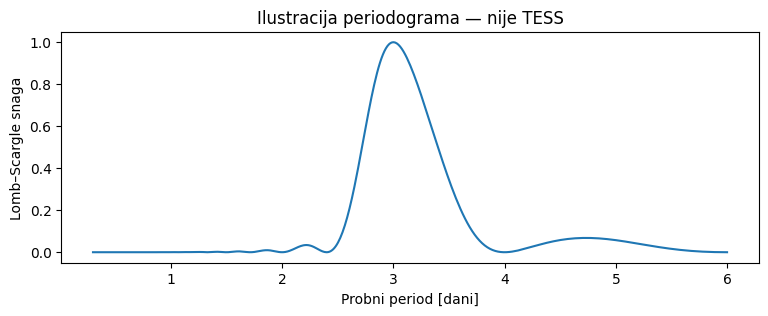

In [13]:
# Kratka demonstracija načina pozivanja LombScargle (nije TESS)
t_example = np.linspace(0, 12, 180)
y_example = np.sin(2*np.pi*t_example/3.0)
freq = np.linspace(1/6, 1/0.3, 2000)  # ciklusi po danu
power = LombScargle(t_example, y_example).power(freq)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(1/freq, power)
ax.set(xlabel="Probni period [dani]", ylabel="Lomb–Scargle snaga",
       title="Ilustracija periodograma — nije TESS")
plt.show()



### Zadatak 4

1. Primenite Lomb–Scargle na seriju koju ste očistili u Zad. 2, **pre agresivnog detrendinga**. Eksplicitno navedite interval ispitivanih perioda.
2. Odredite najizraženije pikove i njihove periode. Da li pokrivaju dovoljno ciklusa unutar osnovice?
3. Proverite **harmonike** (npr. $P/2$ i $2P$) i moguće alijase. Uporedite periodogram očišćene i blago detrendovane serije ili dve polovine iste serije.
4. Iscrtajte krivu presavijenu (phase-folded) na izabrani kandidat-period i ocenite ponovljivost.
5. Napišite **kandidat za period**, a ne potvrđeni period rotacije, ako provere nisu dovoljne.


Osnovica T_span = 27.88 d | ispitivani periodi: 0.2 – 13.94 d (T_span/2) | broj frekvencija: 2749


,P [d],LS snaga,ciklusa u osnovici,FAP
0,5.023442,0.016272,5.55,1.570969e-62
1,2.362721,0.015006,11.80,1.887588e-57
2,6.718098,0.014963,4.15,2.822990e-57
3,4.100016,0.009819,6.80,1.021618e-36
4,0.569563,0.006840,48.95,6.959136e-25



Harmonici za P = 5.023 d:
  P/2 = 2.512 d -> najbliži pik 2.363 d, snaga 0.015 (osnovni: 0.016)
  2P  = 10.047 d -> najbliži pik 9.293 d, snaga 0.003 (osnovni: 0.016)
  Spektralni prozor oko P_kand: snaga 0.033 (blizu 1 → moguć alijas uzorkovanja)
  Orbita TESS-a ≈ 13.7 d, pa su podharmonici ~6.85 d i ~13.7 d sumnjivi na sistematiku.


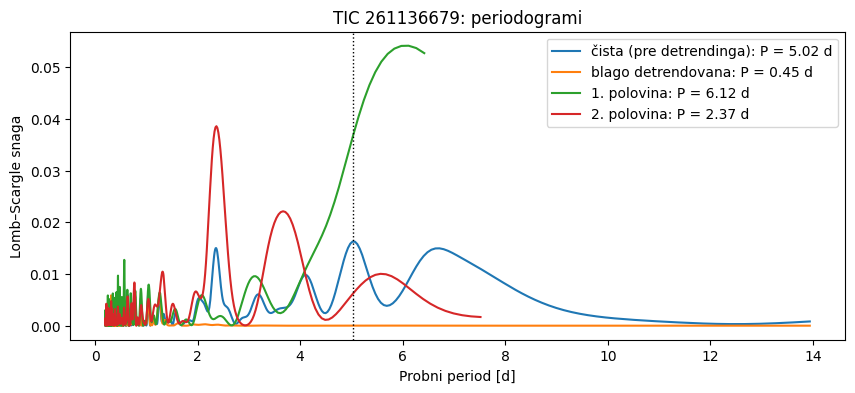

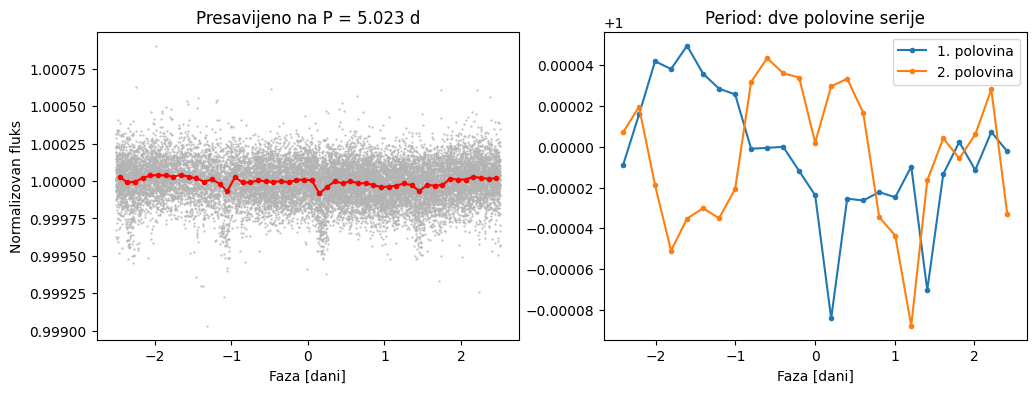


Korelacija profila (1. vs 2. polovina): r = -0.34 | amplituda foldovane krive ≈ 125 ppm | ciklusa: 5.5
ZAKLJUČAK: P ≈ 5.02 d je NEPOUZDAN kandidat (ciklusa: 5.5, r = -0.34, polovine se ne slažu); period rotacije nije utvrđen.


In [14]:
from scipy.signal import find_peaks

def ls_run(t, y, dy=None, pmin=0.2):
    span = t.max() - t.min()
    pmax = span / 2
    ls = LombScargle(t, y, dy)
    fr, pw = ls.autopower(minimum_frequency=1/pmax, maximum_frequency=1/pmin, samples_per_peak=20)
    return ls, fr, pw, span, pmax

def top_peaks(fr, pw, n=5):
    idx, _ = find_peaks(pw)
    idx = idx[np.argsort(pw[idx])[::-1][:n]]
    return [(1/fr[i], pw[i]) for i in idx]

def power_near(fr, pw, P, frac=0.08):
    m = (1/fr > P*(1-frac)) & (1/fr < P*(1+frac))
    return (1/fr[m][np.argmax(pw[m])], pw[m].max()) if m.any() else (np.nan, np.nan)

t, y = arr(lc_pre_detrending.time), arr(lc_pre_detrending.flux)
dy = arr(lc_pre_detrending.flux_err)
dy = dy if np.all(np.isfinite(dy)) and np.all(dy > 0) else None
PMIN = 0.2
ls, fr, pw, span, pmax = ls_run(t, y, dy, PMIN)
print(f"Osnovica T_span = {span:.2f} d | ispitivani periodi: {PMIN} – {pmax:.2f} d (T_span/2) "
      f"| broj frekvencija: {len(fr)}")

# 4.2 Pikovi
rows = []
for P, p in top_peaks(fr, pw):
    fap = ls.false_alarm_probability(p, minimum_frequency=1/pmax, maximum_frequency=1/PMIN)
    rows.append((P, p, span/P, fap))
peak_df = pd.DataFrame(rows, columns=["P [d]", "LS snaga", "ciklusa u osnovici", "FAP"])
display(peak_df)
P_cand = peak_df.iloc[0]["P [d]"]

# 4.3 Harmonici, alijasi, poređenje sa detrendovanom serijom i polovinama
print(f"\nHarmonici za P = {P_cand:.3f} d:")
for lab, Pt in [("P/2", P_cand/2), ("2P", 2*P_cand)]:
    if PMIN <= Pt <= pmax:
        Pf, pf = power_near(fr, pw, Pt)
        print(f"  {lab:3s} = {Pt:.3f} d -> najbliži pik {Pf:.3f} d, snaga {pf:.3f} (osnovni: {peak_df.iloc[0]['LS snaga']:.3f})")
    else:
        print(f"  {lab:3s} = {Pt:.3f} d -> van ispitivanog opsega [{PMIN}, {pmax:.2f}]")

# prozorska funkcija (spectral window): da li kandidat leži na pikovima uzorkovanja?
wls = LombScargle(t, np.ones_like(t), fit_mean=False, center_data=False)
wpw = wls.power(fr)
wP, wp = power_near(fr, wpw, P_cand)
print(f"  Spektralni prozor oko P_kand: snaga {wp:.3f} (blizu 1 → moguć alijas uzorkovanja)")
print(f"  Orbita TESS-a ≈ 13.7 d, pa su podharmonici ~6.85 d i ~13.7 d sumnjivi na sistematiku.")

halves = {"1. polovina": t < np.median(t), "2. polovina": t >= np.median(t)}
curves = {"čista (pre detrendinga)": (fr, pw)}
res = {"čista (pre detrendinga)": P_cand}
if "lc_flat" in globals():
    _, f2, p2, _, _ = ls_run(arr(lc_flat.time), arr(lc_flat.flux), None, PMIN)
    curves["blago detrendovana"] = (f2, p2); res["blago detrendovana"] = top_peaks(f2, p2, 1)[0][0]
for name, mk in halves.items():
    _, f3, p3, _, _ = ls_run(t[mk], y[mk], None, PMIN)
    curves[name] = (f3, p3); res[name] = top_peaks(f3, p3, 1)[0][0]
fig, ax = plt.subplots(figsize=(10, 4))
for name, (f_, p_) in curves.items():
    ax.plot(1/f_, p_, label=f"{name}: P = {res[name]:.2f} d")
ax.axvline(P_cand, c="k", ls=":", lw=1)
ax.set(xlabel="Probni period [d]", ylabel="Lomb–Scargle snaga", title=f"{TARGET}: periodogrami")
ax.legend(); plt.show()

# 4.4 Presavijena kriva
fold = lc_pre_detrending.fold(period=P_cand)
fb = fold.bin(time_bin_size=P_cand/50)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(arr(fold.phase)*1.0, arr(fold.flux), ".", ms=1, c="0.7")
axs[0].plot(arr(fb.phase), arr(fb.flux), "r.-")
axs[0].set(xlabel="Faza [dani]", ylabel="Normalizovan fluks", title=f"Presavijeno na P = {P_cand:.3f} d")
for name, mk in halves.items():
    fh = lc_pre_detrending[mk].fold(period=P_cand).bin(time_bin_size=P_cand/25)
    axs[1].plot(arr(fh.phase), arr(fh.flux), ".-", label=name)
axs[1].legend(); axs[1].set(xlabel="Faza [dani]", title="Period: dve polovine serije")
plt.show()

# Ponovljivost: korelacija binovanih krivih iz dve polovine
bins = np.linspace(-P_cand/2, P_cand/2, 26)
prof = []
for mk in halves.values():
    fh = lc_pre_detrending[mk].fold(period=P_cand)
    ph, fl = arr(fh.phase), arr(fh.flux)
    prof.append([np.nanmedian(fl[(ph >= bins[i]) & (ph < bins[i+1])]) for i in range(25)])
r = np.corrcoef(np.array(prof, float)[:, np.isfinite(np.array(prof, float)).all(0)])[0, 1]
amp = 1e6 * (np.nanmax(arr(fb.flux)) - np.nanmin(arr(fb.flux)))
cycles = span / P_cand
agree = abs(res["1. polovina"] - res["2. polovina"]) / P_cand < 0.15
print(f"\nKorelacija profila (1. vs 2. polovina): r = {r:.2f} | amplituda foldovane krive ≈ {amp:.0f} ppm | ciklusa: {cycles:.1f}")

# 4.5 Formulacija
if cycles >= 2 and r > 0.7 and agree:
    print(f"ZAKLJUČAK: P ≈ {P_cand:.2f} d je KANDIDAT za rotacioni period (≥2 ciklusa, ponovljivo u obe polovine); "
          f"nije potvrđen dok se ne proveri SAP, alijasi i harmonici.")
else:
    print(f"ZAKLJUČAK: P ≈ {P_cand:.2f} d je NEPOUZDAN kandidat (ciklusa: {cycles:.1f}, r = {r:.2f}, "
          f"polovine se {'slažu' if agree else 'ne slažu'}); period rotacije nije utvrđen.")




**Opseg i pikovi.** Ispitani su periodi 0,2 – 13,94 d (T_span/2, T_span = 27,88 d). Najviši pik je P = 5,02 d (5,5 ciklusa), a slede 2,36 d, 6,72 d, 4,10 d i 0,57 d. Sve snage su vrlo niske (≈ 0,016, tj. ~1,6 % varijanse), a vrednosti FAP (~10⁻⁶²) ne treba shvatiti kao potvrdu: pretpostavljaju beli šum, a ovde postoje korelisani šum i ponovljeni padovi.

**Harmonici i alijasi.** Na P/2 ≈ 2,5 d postoji pik (2,36 d) sličnog intenziteta (0,015 prema 0,016), ali nije tačan harmonik jer odstupa ≈ 6 %. Na 2P ≈ 10 d snaga je zanemarljiva (0,003). Snaga spektralne prozorske funkcije kod 5,02 d je mala (0,033), pa pik nije očigledan alijas uzorkovanja.

**Poređenje serija.** Blago detrendovana serija ima praktično ravan periodogram (najviši pik 0,45 d, snaga ≈ 0), jer prozor od 2 d uklanja sve što bi moglo biti na periodima od dana. Polovine serije se ne slažu: 1. polovina daje 6,12 d (pik na samom kraju svog opsega), 2. polovina 2,37 d.

**Presavijena kriva.** Amplituda je samo ≈ 125 ppm, a profili polovina nisu ponovljivi (korelacija r = −0,34, polovine su u protivfazi). Na presavijenoj krivoj se vide **dva uska pada**, na fazama ≈ −1 d i ≈ +0,2 d (razmak ≈ 1,25 d). To odgovara petorici padova iz Zadatka 3 sa periodom ≈ 6,3 d: pri savijanju na 5,02 d takvi padovi padaju na dve faze, čiji je razmak 6,3 − 5,02 ≈ 1,3 d. Pik na 5,02 d zato verovatno potiče od tih padova (hipoteza, ne potvrda), a ne od rotacije.

**Zaključak.** P ≈ 5,02 d je **nepouzdan kandidat** i ne tvrdi se kao rotacioni period: ima ≥ 2 ciklusa, ali se ne ponavlja u polovinama i verovatno je artefakt padova. Period rotacije iz ovih podataka nije utvrđen. Za pouzdaniji pokušaj trebalo bi maskirati padove i uporediti sa SAP fluksom.

## 7. Teorija: šta je flare kandidat?

Optički flare često daje brz porast fluksa, a zatim sporiji pad. Međutim, sličnu sliku mogu dati kosmički zraci, problemi sa pozadinom, loša kadenca ili drugi instrumentalni događaji. Poželjno je da sumnjivi događaj obuhvata **više uzastopnih validnih merenja** i da se proveri neposredno okruženje; ni tada oblik sam po sebi ne garantuje potvrdu.

Jednostavna lokalna mera odstupanja koristi robusnu skalu

$$\sigma_{\rm robust} \approx 1.4826\,\mathrm{median}\bigl(|F_i - \mathrm{median}(F)|\bigr).$$

Globalni prag, npr. $3\sigma$, **nije dovoljan kriterijum**: potrebno je ispitati lokalnu osnovnu liniju, trajanje, kvalitet merenja i šum. Ne označavajte samostalni pojedinačni outlier kao potvrđen bljesak.

### Zadatak 5

1. Napravite meru lokalnog baznog fluksa (npr. pokretni medijan) i obrazložite prozor.
2. Pronađite nekoliko **kandidata**, koristeći relativno odstupanje u odnosu na bazni fluks i robustnu skalu šuma.
3. Za svaki kandidat zabeležite vreme, vršno relativno povećanje i broj uzastopnih validnih kadenci.
4. Nacrtajte uvećanja i proverite zastavice (problematičnosti) kvaliteta i blizinu velikih prekida.
5. Razvrstajte nalaze kao *uverljiv kandidat / nejasan događaj / verovatna sistematika* uz objašnjenje. Ako nema uverljivih kandidata, to je legitiman rezultat.


In [15]:
# ZADATAK 5 — flare kandidati
t, f = arr(lc_pre_detrending.time), arr(lc_pre_detrending.flux)
dt_med = np.median(np.diff(t))

# 5.1 Lokalni bazni fluks: vremenski pokretni medijan (centriran)
WIN_H = 6.0
s = pd.Series(f, index=pd.to_datetime(t, unit="D"))
base = s.rolling(f"{WIN_H}h", center=True, min_periods=15).median().values
if "P_cand" in globals():
    print(f"Prozor {WIN_H} h = {WIN_H/24:.2f} d vs P_kand/10 = {P_cand/10:.2f} d "
          f"({'OK, prozor < P/10' if WIN_H/24 < P_cand/10 else 'prozor je prevelik u odnosu na modulaciju!'})")
print("Obrazloženje: 6 h ≫ trajanje tipičnog flare-a (min–h), pa medijan nije povučen događajem, "
      "a ≪ dane rotacione modulacije, pa prati sporu promenu.")

rel = f / base - 1
ok = np.isfinite(rel)
sig = 1.4826 * np.median(np.abs(rel[ok] - np.median(rel[ok])))
print(f"Robustan šum σ_rob = {sig*1e6:.0f} ppm")

# 5.2–5.3 Kandidati: >= 3 uzastopne validne kadence iznad 3σ
N_MIN, K = 3, 3.0
above = ok & (rel > K * sig)
groups, cur = [], []
for i in np.where(above)[0]:
    if cur and (i == cur[-1] + 1) and (t[i] - t[cur[-1]] < 1.5 * dt_med):
        cur.append(i)
    else:
        if len(cur) >= N_MIN: groups.append(cur)
        cur = [i]
if len(cur) >= N_MIN: groups.append(cur)
# spoji grupe razdvojene < 30 min (isti događaj sa kratkim spuštanjem ispod praga)
merged = []
for g in groups:
    if merged and t[g[0]] - t[merged[-1][-1]] < 30/1440:
        merged[-1] = list(range(merged[-1][0], g[-1] + 1))
    else:
        merged.append(list(g))
groups = merged

# 5.4 Provera zastavica i prekida (koristi sve kadence iz lc_raw)
t_raw, q_raw = arr(lc_raw.time), np.asarray(lc_raw.quality).astype(int)
gaps = np.diff(t); gi = np.where(gaps > 0.2)[0]
gap_edges = np.r_[t[gi], t[gi+1], t.min(), t.max()]
bkg_all = arr(lc_clean["sap_bkg"]) if "sap_bkg" in lc_clean.columns else None

rows = []
for g in groups:
    ip = g[np.argmax(rel[g])]; tp = t[ip]
    near_raw = (t_raw > tp - 0.1) & (t_raw < tp + 0.1)
    n_flag = int((q_raw[near_raw] != 0).sum())
    d_gap = np.min(np.abs(gap_edges - tp))
    bkg_ratio = np.nan
    if bkg_all is not None:
        loc = (t > tp - 0.5) & (t < tp + 0.5); ev = np.array(g)
        bkg_ratio = np.nanmedian(bkg_all[ev]) / np.nanmedian(bkg_all[loc])
    rise, decay = ip - g[0] + 1, g[-1] - ip + 1
    if n_flag > 0 or d_gap < 0.25 or (np.isfinite(bkg_ratio) and bkg_ratio > 1.3):
        cls = "verovatna sistematika"
    elif len(g) >= 4 and decay >= rise:
        cls = "uverljiv kandidat"
    else:
        cls = "nejasan događaj"
    rows.append(dict(t_peak=tp, amplituda_ppm=1e6*rel[ip], n_uzastopnih=len(g), rise=rise, decay=decay,
                     flagovane_okolo=n_flag, dist_do_prekida_d=d_gap, bkg_odnos=bkg_ratio, klasa=cls, idx=g))
cand = pd.DataFrame(rows)
print(f"Pronađeno grupa (≥{N_MIN} uzastopnih kadenci > {K}σ): {len(cand)}")
if len(cand):
    display(cand.drop(columns="idx"))
else:
    print("Nema kandidata — to je legitiman rezultat za ovu seriju i ove kriterijume.")

# Uvećanja (do 6)
if len(cand):
    n = min(6, len(cand))
    fig, axs = plt.subplots((n+1)//2, 2, figsize=(11, 3*((n+1)//2)), squeeze=False)
    norm0 = np.median(arr(lc_clean.flux))
    f_raw_all = arr(lc_raw.flux) / norm0
    for ax, (_, r) in zip(axs.ravel(), cand.sort_values("amplituda_ppm", ascending=False).head(n).iterrows()):
        w = (t > r.t_peak - 0.3) & (t < r.t_peak + 0.3)
        wr = (t_raw > r.t_peak - 0.3) & (t_raw < r.t_peak + 0.3)
        ax.plot(t[w], f[w], ".", ms=3, c="k", label="quality = 0")
        ax.plot(t[w], base[w], "b-", lw=1, label="bazni fluks")
        bad = wr & (q_raw != 0)
        ax.plot(t_raw[bad], f_raw_all[bad], "rx", label="označene kadence")
        ax.plot(t[r.idx], f[r.idx], "o", c="orange", ms=5, label="kandidat")
        ax.set_title(f"t={r.t_peak:.3f} | {r.klasa}", fontsize=9); ax.set_xlabel("BTJD [d]")
    axs[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()


Prozor 6.0 h = 0.25 d vs P_kand/10 = 0.50 d (OK, prozor < P/10)
Obrazloženje: 6 h ≫ trajanje tipičnog flare-a (min–h), pa medijan nije povučen događajem, a ≪ dane rotacione modulacije, pa prati sporu promenu.
Robustan šum σ_rob = 119 ppm
Pronađeno grupa (≥3 uzastopnih kadenci > 3.0σ): 0
Nema kandidata — to je legitiman rezultat za ovu seriju i ove kriterijume.


**Metoda.** Bazni fluks je pokretni medijan od 6 h na seriji pre detrendinga. Prozor je mnogo duži od tipičnog flare-a (minuti–sati), pa ga medijan ne „upija“, a kraći je od modulacije od više dana, pa prati sporu promenu. Robusni šum (MAD) iznosi σ_rob = 119 ppm, pa je prag 3σ ≈ 360 ppm. Kandidat je grupa od najmanje 3 uzastopne validne kadence (≥ 6 min) iznad praga. Klasifikacija je heuristika: verovatna sistematika ako su u okolini označene kadence, ako je događaj blizu prekida ili ako je pozadina povećana; *uverljiv kandidat* ako ima ≥ 4 kadence i pad nije brži od rasta; ostalo je *nejasan događaj*.

**Rezultat.** Pronađeno je 0 kandidata. To je legitiman rezultat. Pojedinačne tačke iznad praga (npr. ≈ +900 ppm oko BTJD 1348,43) ne ispunjavaju uslov od 3 uzastopne kadence, pa se ne računaju kao flare. Periodični padovi iz Zadatka 3 su negativni, pa ni oni nisu kandidati.

**Ograničenja.** Rezultat važi samo za ovaj prag i ovu seriju: flare-ovi niži od ≈ 360 ppm ili kraći od 3 kadence ne mogu se otkriti. U delu BTJD ≈ 1347–1349,3 mnogo je kadenci uklonjeno maskom `quality == 0`, pa se tamo uslov uzastopnosti teško ispunjava i događaji bi mogli ostati neprimećeni. Odsustvo kandidata je u skladu sa optički mirnom krivom, ali ne dokazuje da zvezda nema flare-ove.

## 8. Teorija: ilustrativni XUV i atmosferski escape

Jedan vrlo pojednostavljen, *energy-limited* model gubitka atmosfere glasi

$$\dot M_{\rm esc}=\eta\,\frac{\pi R_{\rm XUV}^{3} F_{\rm XUV}}{G M_p K_{\rm tide}},$$

u uobičajenoj aproksimaciji sa efektivnim apsorpcionim poluprečnikom $R_{\rm XUV}$ i plimnim korekcionim faktorom $K_{\rm tide}$; **model je ilustrativan**, nije univerzalan opis hidrodinamičkog bega. $\eta$ je efikasnost, $F_{\rm XUV}$ upadni XUV fluks, a $M_p$ masa planete.

Ako pretpostavimo konstantne parametre, $\Delta M \approx \dot M\Delta t$. U realnosti XUV opada/evoluira sa vremenom, a apsorpcioni poluprečnik, efikasnost, hlađenje, hemijski sastav i režim bekstva mogu se menjati. Za strožu procenu potreban je evolucioni model.

**Ključno ograničenje:** U ovoj vežbi $F_{\rm XUV}$ je **pretpostavljeni scenario**. Ne izvodi se neposredno iz TESS optičke krive niti iz izdvojenih flare kandidata.

In [16]:
# Pokazni kod: samo računanje primljenog XUV fluksa iz ZADATE luminoznosti.
# Brojevi su proizvoljne ilustrativne pretpostavke, NE merenja iz TESS-a.
from astropy import units as u
L_xuv_demo = 1e-5 * (3.828e26 * u.W)  # pretpostavljena XUV luminosnost
r_demo = 0.1 * u.au                    # primer udaljenosti planete
F_xuv_demo = (L_xuv_demo / (4*np.pi*r_demo**2)).to(u.W/u.m**2)
print("Ilustrativni, neopaženi F_XUV:", F_xuv_demo)

Ilustrativni, neopaženi F_XUV: 1.3611664654085756 W / m2


### Zadatak 6

1. Definišite **hipotetičku** stenovitu planetu: $M_p$, $R_p$, udaljenost od zvezde i vremenski interval $\Delta t$.
2. Uzmite barem **tri pretpostavljena** nivoa $F_{\rm XUV}$ (nizak, srednji, visok) i navedite da nisu izmereni TESS-om.
3. Uz eksplicitne pretpostavke za $\eta$, $R_{\rm XUV}$ i $K_{\rm tide}$ izračunajte $\dot M$ i $\Delta M$. Prikažite rezultat i kao deo mase planete.
4. Ponovite račun sa različitim $\eta$ i procenite osetljivost rezultata na model.
5. U jednoj rečenici napišite zašto to **nije dokaz da posmatrana planeta gubi atmosferu**.



In [17]:
G = 6.674e-11 
M_E = 5.972e24 
R_E = 6.371e6 
L_sun = 3.828e26 
AU = 1.496e11 
GYR = 3.156e16 

# hipoteticka stenovita planeta
Mp = 1.5 * M_E; Rp = 1.15 * R_E
L_star = 0.0025 * L_sun        #  M-patuljasta zvezda
a = 0.05 * AU                  # unutar tipične HZ
dt = 1.0 * GYR                 # vremenski interval
S = L_star / (4*np.pi*a**2)
print(f"Bolometrijski fluks na planeti: {S:.0f} W/m² (= {S/1361:.2f} S_⊕)")

# razliciti nivoi fluxa
f_xuv = {"nizak (1e-4 L_bol)": 1e-4, "srednji (1e-3 L_bol)": 1e-3, "visok (1e-2 L_bol)": 1e-2}
F_xuv = {k: v * S for k, v in f_xuv.items()}  

eta, Rxuv_fac, K_tide = 0.1, 1.2, 1.0   
def mdot(F, eta=eta, Rxuv_fac=Rxuv_fac, K=K_tide):
    return eta * np.pi * (Rxuv_fac*Rp)**3 * F / (G * Mp * K)   # kg/s

M_ocean, M_atm = 1.4e21, 5.1e18  # masa Zemljinih okeana / atmosfere [kg]
rows = []
for k, F in F_xuv.items():
    md = mdot(F); dM = md * dt
    rows.append((k, F, F/1e-3, md, dM, dM/Mp, dM/M_atm, dM/M_ocean))
df = pd.DataFrame(rows, columns=["scenario", "F_XUV [W/m²]", "F_XUV [erg/s/cm²]", "Mdot [kg/s]",
                                 f"ΔM za {dt/GYR:.0f} Gyr [kg]", "ΔM/Mp", "ΔM/M_atm(⊕)", "ΔM/M_okean(⊕)"])
pd.set_option("display.float_format", lambda x: f"{x:.3g}")
display(df)
print("Pretpostavke: η = %.2f, R_XUV = %.1f R_p, K_tide = %.1f, M_p = 1.5 M⊕, R_p = 1.15 R⊕, a = 0.05 au" % (eta, Rxuv_fac, K_tide))


mid = F_xuv["srednji (1e-3 L_bol)"]
print("\nOsetljivost (srednji scenario):")
sens = []
for e in (0.01, 0.1, 0.3):
    md = mdot(mid, eta=e); sens.append(("η = %.2f" % e, md, md*dt/Mp, md*dt/M_atm))
for r in (1.0, 1.5):
    md = mdot(mid, Rxuv_fac=r); sens.append(("R_XUV = %.1f R_p" % r, md, md*dt/Mp, md*dt/M_atm))
for kt in (0.5, 1.0):
    md = mdot(mid, K=kt); sens.append(("K_tide = %.1f" % kt, md, md*dt/Mp, md*dt/M_atm))
display(pd.DataFrame(sens, columns=["varijacija", "Mdot [kg/s]", "ΔM/Mp", "ΔM/M_atm(⊕)"]))
print("η u opsegu 0.01–0.3 menja rezultat 30×, a R_XUV ∝ R³ menja ga kubno — nepouzdanost modela (red veličine) "
      "je veća od razlike između susednih scenarija XUV-a.")


Bolometrijski fluks na planeti: 1361 W/m² (= 1.00 S_⊕)


,scenario,F_XUV [W/m²],F_XUV [erg/s/cm²],Mdot [kg/s],ΔM za 1 Gyr [kg],ΔM/Mp,ΔM/M_atm(⊕),ΔM/M_okean(⊕)
0,nizak (1e-4 L_bol),0.136,136,4.86e+04,1.53e+21,0.000171,301,1.1
1,srednji (1e-3 L_bol),1.36,1.36e+03,4.86e+05,1.53e+22,0.00171,3.01e+03,11
2,visok (1e-2 L_bol),13.6,1.36e+04,4.86e+06,1.53e+23,0.0171,3.01e+04,110


Pretpostavke: η = 0.10, R_XUV = 1.2 R_p, K_tide = 1.0, M_p = 1.5 M⊕, R_p = 1.15 R⊕, a = 0.05 au

Osetljivost (srednji scenario):


,varijacija,Mdot [kg/s],ΔM/Mp,ΔM/M_atm(⊕)
0,η = 0.01,4.86e+04,0.000171,301
1,η = 0.10,4.86e+05,0.00171,3.01e+03
2,η = 0.30,1.46e+06,0.00514,9.02e+03
3,R_XUV = 1.0 R_p,2.81e+05,0.000991,1.74e+03
4,R_XUV = 1.5 R_p,9.49e+05,0.00334,5.88e+03
5,K_tide = 0.5,9.72e+05,0.00343,6.02e+03
6,K_tide = 1.0,4.86e+05,0.00171,3.01e+03


η u opsegu 0.01–0.3 menja rezultat 30×, a R_XUV ∝ R³ menja ga kubno — nepouzdanost modela (red veličine) je veća od razlike između susednih scenarija XUV-a.


Hipotetička planeta (M = 1.5 M⊕, R = 1.15 R⊕) na 0.05 au od M-patuljka L = 0.0025 L☉ prima ≈ 1 S⊕ bolometrijski fluks. Za Δt = 1 Gyr, η = 0.1, R_XUV = 1.2 R_p, K_tide = 1 model daje ΔM/M_p ≈ 1.7·10⁻⁴ (nizak), 1.7·10⁻³ (srednji) i 1.7·10⁻² (visok scenario); to je ≈ 300 / 3 000 / 30 000 masa Zemljine atmosfere, odnosno ≈ 1 / 11 / 110 masa Zemljinih okeana. Dakle, planeta ne gubi značajan deo *ukupne* mase, ali gubitak može biti veliki u odnosu na *atmosferu i vodu*. Rezultat je linearan po η i F_XUV, kubno zavisi od R_XUV i obrnuto od K_tide, pa je neizvesnost modela (faktor 30 samo od η ∈ [0.01, 0.3]) veća od razlike između susednih scenarija.

 Ovo nije dokaz da posmatrana planeta gubi atmosferu: planeta, F_XUV i parametri modela su pretpostavljeni, a XUV se ne može izvesti iz optičke TESS krive.


### Zadatak 7

Napišite **150–250 reči**: Ako je planeta u nastanjivoj zoni, šta nam svetlosna kriva aktivne zvezde govori, a šta ne govori o nastanjivosti? Povežite periodičnost, flare kandidate, pretpostavljeno XUV okruženje i neizvesnosti atmosferskog bekstva. Eksplicitno razdvojite **merenja**, **interpretacije** i **pretpostavke**.



**Merenja.** TESS SPOC svetlosna kriva Pi Mensae (sektor 1, kadenca 120 s) ima šum od ≈ 113–119 ppm po kadenci i ravan tok bez očigledne rotacione modulacije. Lomb–Scargle daje najviši pik na 5,02 d, ali sa slabom snagom (≈ 0,016), amplitudom ≈ 125 ppm i neponovljivim profilom u dve polovine serije (r = −0,34). Flare kandidata nema: nijedna grupa od ≥ 3 uzastopne kadence ne prelazi 3σ. Uočeni su i ponovljeni padovi od ≈ 300–500 ppm na razmaku od ≈ 6–6,5 d.

**Interpretacije.** Pik od 5,02 d verovatno potiče od tih padova (moguć tranzit), a ne od rotacije, pa period rotacije ostaje neutvrđen. Odsustvo flare-ova znači samo da u ovoj seriji nema događaja iznad ≈ 360 ppm; zvezda deluje optički mirno, ali to ne dokazuje nisku XUV aktivnost.

**Pretpostavke.** XUV fluks u Zadatku 6 je pretpostavljen (10⁻⁴–10⁻² L_bol), kao i planeta i parametri η, R_XUV i K_tide. Rezultat se menja ≈ 30 puta samo zbog η, pa je gubitak atmosfere neodređen za red veličine.

**Zaključak.** Svetlosna kriva ne govori o sastavu atmosfere, vodi, magnetnom polju ni stvarnom XUV zračenju, jer se XUV ne izvodi iz optičke krive. Ona samo ograničava optičku aktivnost zvezde; za procenu nastanjivosti potrebni su XUV posmatranja i atmosferska merenja.


## Reference i korisni linkovi

- [Lightkurve dokumentacija](https://lightkurve.github.io/lightkurve/)
- [MAST arhiva](https://mast.stsci.edu/)
- [TESS misija (NASA)](https://science.nasa.gov/mission/tess/)
- [Lightkurve — izbor quality bitmaske](https://lightkurve.github.io/lightkurve/reference/api/lightkurve.SearchResult.download.html)
- [Astropy Lomb–Scargle](https://docs.astropy.org/en/stable/timeseries/lombscargle.html)

